# 01 Stations, data and sensor orientation (stages G1 and G2)

The record of the inputs of every later stage, as frozen for detection on 16 October 2026:
1. **Station table.** One chosen sensor per code within 100 km of the cluster (35.0000 N, 127.7286 E), by the Haenam sensor rule with the coverage-first addition (G-D1, G-D1b); temporary codes of 2023 read as their site (G-D7); predecessor codes linked until their successor starts (G-D10); KS.KWJ excluded (G-D20).
2. **Continuous data.** The MARA mirror, the KIGAM fill of the KG stations after 2024-10-31 (G-D14), the NECIS re-fetch of components missing in the 2021 episode (G-D13), the link tree that every stage reads, and an audit of every chosen station-day.
3. **Sensor orientation.** The dated orientation table: the national study's periods (33) and this study's measurements from local day files (G2), with the check of one against the other.

The notebook reads the project tables and logs; it changes nothing.

In [1]:
import os, sys, re, glob, json, subprocess, datetime, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = '/home/msseo/works/73.Gwangyang_sequence'
import pathlib
import matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.colors import ListedColormap, Normalize
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120); pd.set_option('display.max_rows', 200)
# Helvetica as in the Haenam and Imsil reports (pasted verbatim from notebooks/build_90_study_plan_report.py)
FONT_DIR = pathlib.Path.home() / ".local/share/fonts/helvetica-family"
USER_HELVETICA = pathlib.Path.home() / "Downloads/Helvetica/helvetica.ttf"
NIMBUS = "/usr/share/fonts/urw-base35/NimbusSans-{}.otf"
_REGULAR_SRC = (NIMBUS.format("Regular") if os.path.exists(NIMBUS.format("Regular"))
                else str(USER_HELVETICA))
SRC_REGULAR = pathlib.Path(_REGULAR_SRC)
_FACES = [
    (_REGULAR_SRC, "Helvetica-Regular.otf", "Regular", 400, False, False),
    (NIMBUS.format("Bold"), "Helvetica-Bold.otf", "Bold", 700, True, False),
    (NIMBUS.format("Italic"), "Helvetica-Italic.otf", "Italic", 400, False, True),
    (NIMBUS.format("BoldItalic"), "Helvetica-BoldItalic.otf", "Bold Italic", 700,
     True, True),
]
def _set_name(font, name_id, value):
    for rec in font["name"].names:
        if rec.nameID == name_id:
            rec.string = (value.encode("utf-16-be") if rec.platformID == 3
                          else value.encode("latin-1"))
def build_helvetica_family(force=False):
    have = [FONT_DIR / f[1] for f in _FACES]
    if not force and all(p.exists() for p in have):
        return True
    if not SRC_REGULAR.exists():
        return False
    from fontTools.ttLib import TTFont
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    for src, outname, sub, wght, is_bold, is_ital in _FACES:
        if not os.path.exists(src):
            continue
        f = TTFont(src)
        full = "Helvetica" if sub == "Regular" else f"Helvetica {sub}"
        ps = "Helvetica" if sub == "Regular" else "Helvetica-" + sub.replace(" ", "")
        _set_name(f, 1, "Helvetica")
        _set_name(f, 2, sub)
        _set_name(f, 4, full)
        _set_name(f, 6, ps)
        _set_name(f, 16, "Helvetica")
        _set_name(f, 17, sub)
        os2 = f["OS/2"]
        os2.usWeightClass = wght
        fs = os2.fsSelection & ~(1 | (1 << 5) | (1 << 6))
        if is_ital:
            fs |= 1
        if is_bold:
            fs |= (1 << 5)
        if not is_bold and not is_ital:
            fs |= (1 << 6)
        os2.fsSelection = fs
        ms = f["head"].macStyle & ~3
        if is_bold:
            ms |= 1
        if is_ital:
            ms |= 2
        f["head"].macStyle = ms
        f.save(FONT_DIR / outname)
    return (FONT_DIR / _FACES[0][1]).exists()
def use_helvetica(verbose=False):
    ok = build_helvetica_family()
    if ok:
        for f in fm.findSystemFonts([str(FONT_DIR)]):
            fm.fontManager.addfont(f)
    have = {e.name for e in fm.fontManager.ttflist}
    fam = ["Helvetica", "Nimbus Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": fam,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Helvetica",
        "mathtext.it": "Helvetica:italic",
        "mathtext.bf": "Helvetica:bold",
        "mathtext.sf": "Helvetica",
        "mathtext.default": "regular",
        "axes.unicode_minus": False,
        "legend.framealpha": 1.0,
        "legend.facecolor": "white",
        "pdf.fonttype": 42,          # embed TrueType so vector output stays editable
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    })
    resolved = "Helvetica" if "Helvetica" in have else (
        "Nimbus Sans" if "Nimbus Sans" in have else "DejaVu Sans")
    if verbose:
        n = len([e for e in fm.fontManager.ttflist if e.name == "Helvetica"])
        print(f"font family in use: {resolved} ({n} faces registered)")
    return resolved
DPI = 300
assert use_helvetica(verbose=True) == 'Helvetica'
plt.rcParams.update({"font.size": 8, "axes.labelsize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "axes.linewidth": 0.6,
                     "savefig.dpi": 200, "legend.framealpha": 1.0, "legend.edgecolor": "0.3", "legend.fancybox": False})
CEN = (35.0000, 127.7286); W0, W1 = '2012-12-20', '2026-10-06'
def dist_km(lat, lon):
    la0, lo0, la, lo = map(np.radians, (CEN[0], CEN[1], np.asarray(lat, float), np.asarray(lon, float)))
    a = np.sin((la - la0) / 2) ** 2 + np.cos(la0) * np.cos(la) * np.sin((lo - lo0) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))
CHECKS = []
def check(name, ok, detail): CHECKS.append(dict(check=name, result='PASS' if ok else 'FAIL', detail=detail))

font family in use: Helvetica (4 faces registered)


## 1. The station table

`detection/station_table/stations.csv` (frozen) and the inventory behind it (`docs/station_inventory/tables/stations.csv`).

In [2]:
ST = pd.read_csv(f'{ROOT}/detection/station_table/stations.csv', dtype={'LinkUntil': str})
INV = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/stations.csv')
STREAMS = pd.read_csv(f'{ROOT}/registry/streams.csv', dtype=str)
DEC = pd.read_csv(f'{ROOT}/docs/decisions.csv', dtype=str).fillna('').set_index('id')
temp = set(STREAMS.sta[STREAMS.sta != STREAMS.site])
ST['temporary'] = ST.Code.isin(temp); ST['dist_km'] = dist_km(ST.Latitude, ST.Longitude)
ST['last'] = [min(e, u) if isinstance(u, str) and u else e for e, u in zip(ST.End, ST.LinkUntil)]
SITE = ST[~ST.temporary]
print(f'{len(ST)} codes in the table: {len(SITE)} stations ({(SITE.Network == "KS").sum()} KS, {(SITE.Network == "KG").sum()} KG) and {ST.temporary.sum()} temporary codes ({", ".join(sorted(ST.Code[ST.temporary]))})')
print('chosen sensors (stations):', SITE.Sensor.value_counts().to_dict())
print('predecessor codes linked until their successor starts:', ', '.join(f'{r.Code} -> {r.LinkUntil}' for r in ST[ST.LinkUntil.notna() & (ST.LinkUntil != '')].itertuples()))
print('excluded:', DEC.loc['G-D20', 'gwangyang_value'], '|', DEC.loc['G-D20', 'evidence'][:160], '...')
print('20-sps SL channels (G-D12, open):', DEC.loc['G-D12', 'effect_on_counts'])
T1 = INV.merge(ST[['Code', 'Start', 'End', 'LinkUntil']], left_on='sta', right_on='Code', how='inner')[['net', 'sta', 'role', 'dist_km', 'chosen_sensor', 'choice_status', 'Start', 'End', 'LinkUntil', 'in_2021_seq', 'in_2026_seq', 'orientation_periods']]
display(T1.sort_values('dist_km').reset_index(drop=True))
assert set(T1.sta) == set(ST.Code), 'every code of the station table is in the inventory'
n_na = int(INV.choice_status.str.contains('rule not applicable').sum())
check('Sensor rule applies to every multi-sensor station', n_na == 0, f'{n_na} stations where the rule could not be applied')
check('Station table matches the inventory', (T1.chosen_sensor.values == ST.set_index('Code').loc[T1.sta, 'Sensor'].values).all(), f'{len(T1)} codes; sensor and span from the inventory')

115 codes in the table: 110 stations (102 KS, 8 KG) and 5 temporary codes (DAYAT, GEJAT, GWYBT, NAWBT, SUCAT)
chosen sensors (stations): {'HG': 82, 'HH': 14, 'EL': 14}
predecessor codes linked until their successor starts: YSU -> 2016-12-31, NAH -> 2018-07-11, YES -> 2016-12-31, JIN -> 2016-12-31, KCH -> 2016-05-15, HAC -> 2016-12-31, IMS -> 2016-12-31, MAS -> 2016-05-15, MAS2 -> 2018-01-16, NAJ -> 2018-07-12
excluded: KS.KWJ excluded from the inventory and station table | KWJ HH on MARA: 4 files per year 2012-2015 named DOY 000-003 by sequence, holding 01-01, 04-10, 07-19 and 10-27 at 80 Hz, plus 2016-187 at 80 Hz. Linked by name ...
20-sps SL channels (G-D12, open): 2012-12..2015-03: 5 fewer stations within 100 km (1 within 50 km)


,net,sta,role,dist_km,chosen_sensor,choice_status,Start,End,LinkUntil,in_2021_seq,in_2026_seq,orientation_periods
0,KS,GWYB,station,7.1,HH,"only sensor (coverage first: HG not eligible, data period > 365 d shorter)",2012-12-20,2026-10-06,NaN,True,True,2013-01-10..2016-09-23 -125.5; 2016-10-15..2017-07-26 +94.6; 2017-08-11..2023-07-02 -95.2; 2023-07-03..2026-10-06 +45.6
1,KS,GWYBT,"temporary code of GWYB, merged (fills days the site's sensor lacks)",7.1,HH,by the sensor rule,2023-01-12,2023-07-03,NaN,False,False,2023-01-15..2023-07-02 +44.8
2,KS,HAD,station,9.6,HG,only full-period sensor,2016-07-05,2018-07-12,NaN,False,False,2017-01-03..2017-11-15 +0.2
3,KS,PHDA,station,14.3,HG,only sensor,2022-01-05,2026-10-06,NaN,False,True,2022-01-07..2022-08-07 +3.5; 2022-08-23..2026-09-25 -93.1
4,KS,GMNA,station,15.3,HG,only sensor,2018-02-01,2023-12-07,NaN,True,False,2018-02-13..2023-12-07 +4.3
5,KS,BAU,station,16.6,EL,by the sensor rule,2017-01-01,2026-10-06,NaN,True,True,2017-01-02..2026-10-02 +1.5
6,KS,YSU,station,16.6,EL,"only sensor (coverage first: HG not eligible, data period > 365 d shorter)",2015-04-01,2017-05-10,2016-12-31,False,False,2015-04-20..2016-10-30 +4.2
7,KG,JRB,station,25.0,HG,"only sensor (coverage first: HH not eligible, data period > 365 d shorter)",2012-12-20,2026-10-06,NaN,True,True,2010-01-02..2024-10-23 -155.9
8,KS,HWJA,station,25.9,HG,only sensor,2026-01-01,2026-10-06,NaN,False,True,2026-02-04..2026-09-25 +20.6
9,KS,NAHA,station,27.2,HG,only full-period sensor,2018-07-12,2026-10-06,NaN,True,True,2018-07-28..2026-10-06 -1.3


## 2. Stations per year

Codes with data from their chosen sensor in each year (temporary codes excluded), counted from the link tree.

,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
HH,6,6,6,8,9,9,10,12,12,12,12,13,12,12,12
EL,1,2,2,7,9,8,8,7,7,7,7,7,7,6,6
HG,3,3,3,3,21,23,37,42,41,42,44,47,48,63,64
within 100 km,10,11,11,18,39,40,55,61,60,61,63,67,67,81,82
within 60 km,8,8,8,9,16,17,22,24,24,24,25,26,24,28,29
within 50 km,4,4,4,5,11,12,15,15,15,15,16,16,15,18,19


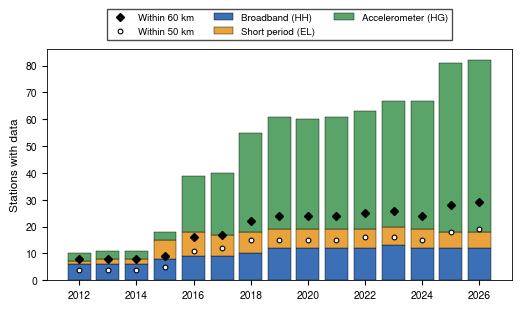

In [3]:
LINK = f'{ROOT}/data/continuous/sds_links'
YRS = list(range(2012, 2027))
days = {}
for r in ST.itertuples():
    have = {}
    for c in 'ZNE':
        d = f'{LINK}/{r.Network}/{r.Code}/{r.Sensor}{c}.D'
        have[c] = {f[-8:] for f in os.listdir(d)} if os.path.isdir(d) else set()
    days[r.Code] = have
cnt = {r: {y: 0 for y in YRS} for r in (50, 60, 100)}
by_sen = {s: {y: 0 for y in YRS} for s in ('HH', 'EL', 'HG')}
for r in SITE.itertuples():
    for y in YRS:
        if any(k.startswith(str(y)) for k in days[r.Code]['Z']):
            by_sen[r.Sensor][y] += 1
            for rad in (50, 60, 100):
                cnt[rad][y] += r.dist_km <= rad
T2 = pd.DataFrame({'HH': by_sen['HH'], 'EL': by_sen['EL'], 'HG': by_sen['HG'], 'within 100 km': cnt[100], 'within 60 km': cnt[60], 'within 50 km': cnt[50]}); display(T2.T)
SENS = {'HH': ('#3b6fb6', 'Broadband (HH)'), 'EL': ('#e8a33d', 'Short period (EL)'), 'HG': ('#5aa469', 'Accelerometer (HG)')}
fig, ax = plt.subplots(figsize=(6.0, 3.0)); bot = np.zeros(len(YRS))
for s_ in SENS:
    v = np.array([by_sen[s_][y] for y in YRS]); ax.bar(YRS, v, bottom=bot, color=SENS[s_][0], edgecolor='k', lw=0.3, width=0.8, label=SENS[s_][1]); bot += v
ax.plot(YRS, [cnt[60][y] for y in YRS], 'D', ms=3.6, color='k', label='Within 60 km'); ax.plot(YRS, [cnt[50][y] for y in YRS], 'o', ms=3.4, mfc='white', mec='k', mew=0.8, label='Within 50 km')
ax.set_ylabel('Stations with data'); ax.set_xticks(YRS[::2]); ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True, fontsize=7)
plt.show()

## 3. Continuous data: sources, link tree and completeness

In [4]:
def total(log, pat):
    m = re.findall(pat, open(f'{ROOT}/{log}').read()); assert m, (log, pat); return m[-1]   # the last (final) total of a log that prints progress lines
mf, mgb, mpr = total('logs/mirror_pull_20261015b.log', r'TOTAL fetched: ([\d,]+) files, ([\d.]+) GB; problems (\d+)')
sf, sgb, spr = total('logs/mirror_pull_20261015_coverage_first.log', r'TOTAL fetched: ([\d,]+) files, ([\d.]+) GB; problems (\d+)')
vf, vgb, vpr = total('logs/mirror_verify_20261016.log', r'TOTAL still missing: ([\d,]+) files, ([\d.]+) GB; problems (\d+)')
kg = total('logs/kigam_fdsn_pull_20261015b.log', r'([\d,]+)/([\d,]+) requests; files written ([\d,]+); errors (\d+)')
jobs = pd.read_csv(f'{ROOT}/logs/necis_refetch_jobs_20261015.csv')
lk = open(f'{ROOT}/logs/link_all_20261016.log').read(); m_ = re.search(r'links: new (\d+), already present (\d+), re-pointed (\d+)', lk)
chk = open(f'{ROOT}/logs/link_check_20261016.log').read()
T3 = pd.DataFrame([('MARA mirror (bulk)', f'{mf} files, {float(mgb):,.1f} GB, problems {mpr}'),
                   ('MARA mirror (coverage-first supplement)', f'{sf} files, {float(sgb):,.1f} GB, problems {spr}'),
                   ('MARA verify', f'{vf} files ({vgb} GB) on MARA not on disk: day 2026-281 (2026-10-08), after the window'),
                   ('KIGAM FDSN fill (KG after 2024-10-31)', f'{kg[0]}/{kg[1]} station-days requested, {kg[2]} files, errors {kg[3]}'),
                   ('NECIS re-fetch (2021 episode)', f'{len(jobs)} requests: ' + ', '.join(f'{k} {v}' for k, v in jobs.outcome.value_counts().items())),
                   ('Link tree', f'{int(m_.group(1)) + int(m_.group(2)):,} links ({m_.group(1)} new on 2026-10-16, re-pointed {m_.group(3)})'),
                   ('Link check', re.search(r'RESULT: (\w+)', chk).group(1))], columns=['item', 'value']); display(T3)
assert vpr == '0'
mv = pd.read_csv(f'{ROOT}/data/continuous/KS_KG_mara_sds/_manifest/r1b_streams/verify_r3x.csv')
check('Pull complete for the window', int(mpr) == 0 and int(spr) == 0 and int(kg[3]) == 0, f'MARA problems {mpr}+{spr}; KIGAM errors {kg[3]}; only 2026-10-08 missing')
check('Link tree consistent', 'RESULT: PASS' in chk, 'link_continuous.py --check: no dangling, misplaced, unplanned or absent links')

,item,value
0,MARA mirror (bulk),"717,147 files, 6,274.6 GB, problems 0"
1,MARA mirror (coverage-first supplement),"64,336 files, 620.7 GB, problems 0"
2,MARA verify,"222 files (1.7 GB) on MARA not on disk: day 2026-281 (2026-10-08), after the window"
3,KIGAM FDSN fill (KG after 2024-10-31),"3,543/3,543 station-days requested, 10,629 files, errors 0"
4,NECIS re-fetch (2021 episode),"11 requests: recovered 8, aborted 2, none at NECIS 1"
5,Link tree,"711,715 links (563324 new on 2026-10-16, re-pointed 0)"
6,Link check,PASS


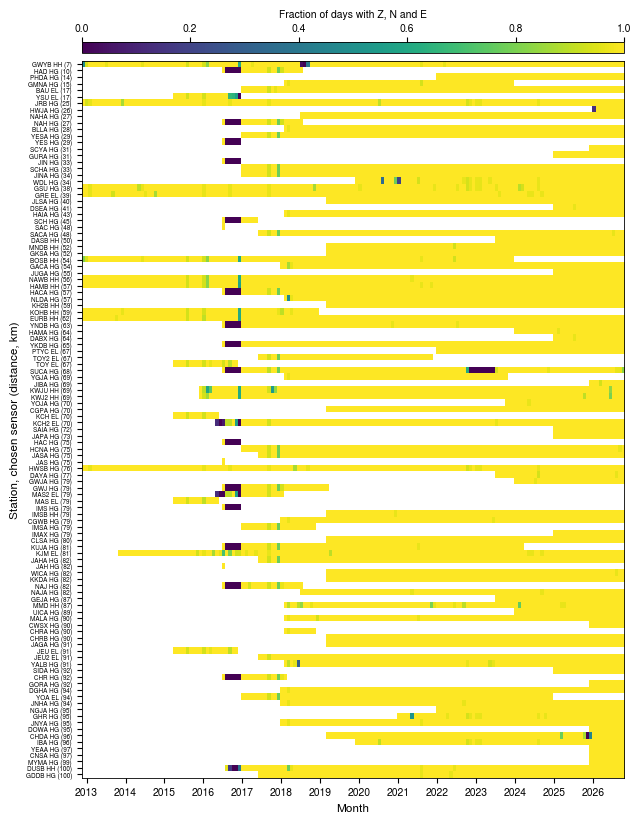

station-days with one or two components missing, 2012-2026: 8


,network,station,sensor,date,year,doy,present,missing,episode,kma_event_day
0,KS,GMNA,HG,2021-08-27,2021,239,NE,Z,2021.0,True
1,KS,GMNA,HG,2021-08-28,2021,240,NE,Z,2021.0,True
2,KS,BOSB,HH,2021-08-27,2021,239,NE,Z,2021.0,True
3,KS,EURB,HH,2016-01-02,2016,2,ZN,E,NaN,False
4,KS,TOY,EL,2016-03-08,2016,68,ZN,E,NaN,False
5,KS,MAS,EL,2016-01-02,2016,2,NE,Z,NaN,False
6,KS,JEU,EL,2016-03-08,2016,68,ZN,E,NaN,False
7,KS,DUSB,HH,2021-08-20,2021,232,NE,Z,2021.0,False


In [5]:
# station-days per month with all three components, for Figure 3 and the audit summary
months = pd.period_range('2012-12', '2026-10', freq='M')
rows_ = SITE.sort_values('dist_km').reset_index(drop=True)
M = np.full((len(rows_), len(months)), np.nan)
for i, r in rows_.iterrows():
    z, n, e = days[r.Code]['Z'], days[r.Code]['N'], days[r.Code]['E']
    full = z & n & e
    for j, p in enumerate(months):
        d0, d1 = max(p.start_time.date(), datetime.date.fromisoformat(max(r.Start, W0))), min(p.end_time.date(), datetime.date.fromisoformat(min(r['last'], W1)))
        if d0 > d1: continue
        ks = [f'{(d0 + datetime.timedelta(k)).year}.{(d0 + datetime.timedelta(k)).timetuple().tm_yday:03d}' for k in range((d1 - d0).days + 1)]
        M[i, j] = np.mean([k in full for k in ks])
fig, ax = plt.subplots(figsize=(7.0, 9.6))
cm = mpl.colormaps['viridis'].copy(); cm.set_bad('white')
im = ax.imshow(np.ma.masked_invalid(M), aspect='auto', cmap=cm, vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(len(rows_))); ax.set_yticklabels([f'{r.Code} {r.Sensor} ({r.dist_km:.0f})' for r in rows_.itertuples()], fontsize=4.6)
jt = [j for j, p in enumerate(months) if p.month == 1]; ax.set_xticks(jt); ax.set_xticklabels([str(months[j].year) for j in jt])
ax.set_xlabel('Month'); ax.set_ylabel('Station, chosen sensor (distance, km)')
cb = fig.colorbar(im, ax=ax, location='top', fraction=0.02, pad=0.01, aspect=50); cb.set_label('Fraction of days with Z, N and E', fontsize=7.5)
plt.show()
AUD = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/component_audit_2012_2013_2014_2015_2016_2017_2018_2019_2020_2021_2022_2023_2024_2025_2026.csv')
print(f'station-days with one or two components missing, 2012-2026: {len(AUD)}'); display(AUD)
check('Component completeness', len(AUD) <= 10, f'{len(AUD)} partial station-days in 2012-2026 (2021: {int((AUD.year == 2021).sum())}, none of them recoverable)')

## 4. Sensor orientation

The dated table `docs/station_inventory/tables/orientation_periods.csv` (used through `registry/orientation.py` by every stage) and the measurements behind the G2 periods.

In [6]:
OP = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/orientation_periods.csv')
PER = pd.read_csv(f'{ROOT}/data/stations/orientation_r1c/Table/periods_r1c.csv'); PM = PER[PER.method == 'P_minT']
CHK = pd.read_csv(f'{ROOT}/data/stations/orientation_r1c/Table/check_local_vs_stp.csv')
nmeas = sum(1 for _ in open(f'{ROOT}/data/stations/orientation_r1c/Table/measurements_r1c.csv')) - 1
print(f'G2: {nmeas:,} station-teleseism windows measured; {len(PM)} P_minT periods for {PM.unit.nunique()} sensors ({int(PM.valid.sum())} valid)')
print(f'local (G2) vs national (33) on the same events, accepted by both: n {len(CHK)}, |diff| median {CHK["diff"].median():.2f}, 95% {CHK["diff"].quantile(0.95):.2f}, max {CHK["diff"].max():.2f} deg')
print('orientation-table rows by source:', OP.source.str.split(';').str[0].value_counts().to_dict())
ch = SITE[['Network', 'Code', 'Sensor', 'dist_km']].merge(OP, left_on=['Network', 'Code', 'Sensor'], right_on=['net', 'sta', 'sensor'], how='left')
T4 = ch.groupby(['Code', 'Sensor', 'dist_km']).apply(lambda g: pd.Series(dict(periods=int(g.start.notna().sum()),
     angles=', '.join(f'{t:.1f}' for t in g.theta_M_apply.dropna()), first=g.start.min(), last=g.end.max()))).reset_index().sort_values('dist_km')
display(T4[T4.dist_km <= 60].reset_index(drop=True))
none_ = T4[T4.periods == 0]
print('chosen sensors without a measured period (treated as unturned and flagged, G-D2):', ', '.join(f'{r.Code} {r.Sensor} ({r.dist_km:.0f} km)' for r in none_.itertuples()))
check('Local orientation measurements reproduce the national study', CHK['diff'].median() <= 0.1 and CHK['diff'].max() <= 1.0, f'n {len(CHK)}; median {CHK["diff"].median():.2f} deg, max {CHK["diff"].max():.2f} deg')
gw = OP[(OP.sta == 'GWYB') & (OP.sensor == 'HH')]
check('GWYB orientation periods', len(gw) == 4, 'GWYB HH: ' + '; '.join(f'{r.theta_M_apply:+.1f} deg {r.start}..{r.end}' for r in gw.itertuples()))

G2: 22,078 station-teleseism windows measured; 147 P_minT periods for 110 sensors (144 valid)
local (G2) vs national (33) on the same events, accepted by both: n 950, |diff| median 0.00, 95% 0.10, max 0.30 deg
orientation-table rows by source: {'33 national': 1387, 'G2: 33 method, full history': 144}


/tmp/ipykernel_2455674/1507758222.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  T4 = ch.groupby(['Code', 'Sensor', 'dist_km']).apply(lambda g: pd.Series(dict(periods=int(g.start.notna().sum()),


,Code,Sensor,dist_km,periods,angles,first,last
0,GWYB,HH,7.134238,4,"-125.5, 94.6, -95.2, 45.6",2013-01-10,2026-10-06
1,HAD,HG,9.619783,1,0.2,2017-01-03,2017-11-15
2,PHDA,HG,14.378306,2,"3.5, -93.1",2022-01-07,2026-09-25
3,GMNA,HG,15.236702,1,4.3,2018-02-13,2023-12-07
4,YSU,EL,16.563537,1,4.2,2015-04-20,2016-10-30
5,BAU,EL,16.563537,1,1.5,2017-01-02,2026-10-02
6,JRB,HG,24.995877,1,-155.9,2010-01-02,2024-10-23
7,HWJA,HG,25.899501,1,20.6,2026-02-04,2026-09-25
8,NAHA,HG,27.198700,1,-1.3,2018-07-28,2026-10-06
9,NAH,HG,27.204738,1,-7.1,2016-07-13,2018-06-21


chosen sensors without a measured period (treated as unturned and flagged, G-D2): YES HG (29 km), SAC HG (48 km), HAC HG (75 km), JAS HG (75 km), JAH HG (82 km), CHR HG (92 km)


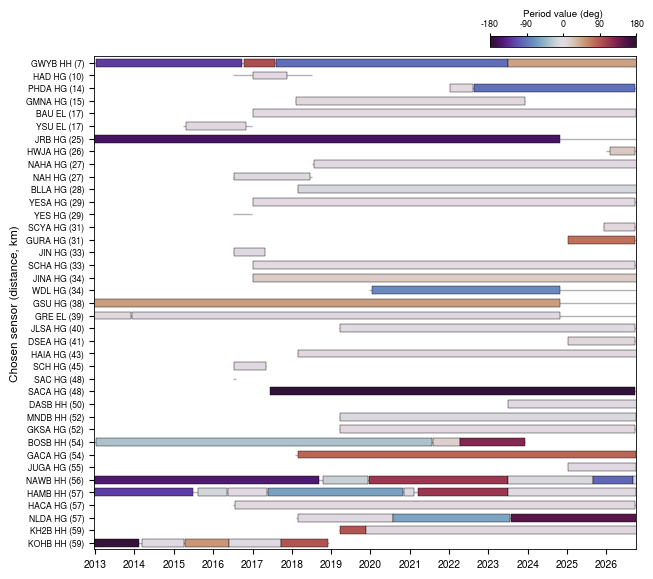

In [7]:
cmap = mpl.colormaps['twilight_shifted']; norm = Normalize(-180, 180)
sel = SITE[SITE.dist_km <= 60].sort_values('dist_km').reset_index(drop=True)
fig, bx = plt.subplots(figsize=(7.0, 6.4))
for i, r in sel.iterrows():
    bx.hlines(i, pd.Timestamp(max(r.Start, W0)), pd.Timestamp(min(r['last'], W1)), color='0.7', lw=1.0, zorder=1)
    for p in OP[(OP.net == r.Network) & (OP.sta == r.Code) & (OP.sensor == r.Sensor)].itertuples():
        t0_, t1_ = mdates.date2num(pd.Timestamp(p.start)), mdates.date2num(pd.Timestamp(p.end) + pd.Timedelta(days=1))
        bx.barh(i, t1_ - t0_, left=t0_, height=0.62, color=cmap(norm(p.theta_M_apply)), edgecolor='k', linewidth=0.3, zorder=2)
bx.set_yticks(range(len(sel))); bx.set_yticklabels([f'{r.Code} {r.Sensor} ({r.dist_km:.0f})' for r in sel.itertuples()], fontsize=6.2)
bx.set_ylim(len(sel) - 0.5, -0.5); bx.set_xlim(pd.Timestamp(W0), pd.Timestamp(W1)); bx.xaxis.set_major_locator(mdates.YearLocator(1)); bx.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
bx.set_ylabel('Chosen sensor (distance, km)')
cax = bx.inset_axes([0.73, 1.02, 0.27, 0.022]); cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation='horizontal')
cb.set_ticks([-180, -90, 0, 90, 180]); cb.ax.tick_params(labelsize=6.5, length=2); cb.ax.xaxis.set_ticks_position('top'); cb.set_label('Period value (deg)', fontsize=7, labelpad=2); cb.ax.xaxis.set_label_position('top')
plt.show()

## 5. The detection freeze

In [8]:
FR = json.load(open(f'{ROOT}/relocation/provenance/adoption/renewal_run_params.json'))
PARAM_FILES = 'pipeline/config.py pipeline/core.py pipeline/pick_augmentation.py station_table/stations.csv /home/msseo/works/14.EQNet/EQNet/docs/model_phasenet_plus/model_99.pth'
now = subprocess.run(['bash', '-c', f'cd {ROOT}/detection && sha256sum {PARAM_FILES} | sha256sum | cut -c1-16'], capture_output=True, text=True).stdout.strip()
print(f'frozen {FR["frozen"]}: hash {FR["hash"]}; recomputed now: {now}; weights sha256 {FR["weights_sha256"][:16]}...; window {FR["window"]}')
check('Detection parameters frozen and unchanged', now == FR['hash'], f'hash {FR["hash"]} (config, core, pick augmentation, station table, weights)')
check('Smoke-test outputs out of the production folder', not os.path.exists(f'{ROOT}/detection/phasenet_plus_2012-2026') and os.path.isdir(f'{ROOT}/detection/smoke_G3_20261015/phasenet_plus_2012-2026'), 'moved to detection/smoke_G3_20261015')

frozen 2026-10-16T12:51:05: hash d724acfddcd608dd; recomputed now: d724acfddcd608dd; weights sha256 f1643330e34bffaa...; window 2012-12-20 .. 2026-10-06


## Comprehensive summary

In [9]:
C = pd.DataFrame(CHECKS); display(C)
print('STAGES G1 + G2:', 'PASS' if (C.result == 'PASS').all() else 'FAIL')
S = pd.DataFrame([
    ('Stations', f'{len(SITE)} codes within 100 km ({(SITE.Network == "KS").sum()} KS, {(SITE.Network == "KG").sum()} KG) + {ST.temporary.sum()} temporary codes; chosen sensors {SITE.Sensor.value_counts().to_dict()}'),
    ('Within 60 km', f'2013: {cnt[60][2013]}, 2016: {cnt[60][2016]}, 2021: {cnt[60][2021]}, 2026: {cnt[60][2026]}'),
    ('Data', f'{float(mgb) + float(sgb):,.1f} GB from MARA, {kg[2]} KIGAM files, {int((jobs.outcome == "recovered").sum())} NECIS recoveries; {int(m_.group(1)) + int(m_.group(2)):,} links'),
    ('Completeness', f'{len(AUD)} partial station-days in 2012-2026'),
    ('Orientation', f'{len(PM)} G2 periods for {PM.unit.nunique()} sensors; local vs national median {CHK["diff"].median():.2f} deg (n {len(CHK)}); {len(none_)} chosen sensors unmeasured'),
    ('Freeze', f'hash {FR["hash"]} at {FR["frozen"]}'),
], columns=['quantity', 'value']); display(S)
print('Take-homes:')
print('1. Every later stage reads one link tree of one chosen sensor per station; it is complete for the window except 8 station-days missing a component and the archive gaps shown in the coverage figure.')
print(f'2. The network grows from {cnt[60][2013]} stations within 60 km in 2013 to {cnt[60][2026]} in 2026: detection sensitivity and completeness must be judged per era.')
print('3. Horizontal orientations change often near the cluster (GWYB four times); every stage uses the one dated table, which the local measurements reproduce to a fraction of a degree.')
print('4. Detection settings and the station table are frozen; production detection (G4) starts when moho\'s GPU is free of the Haenam scan.')

,check,result,detail
0,Sensor rule applies to every multi-sensor station,PASS,0 stations where the rule could not be applied
1,Station table matches the inventory,PASS,115 codes; sensor and span from the inventory
2,Pull complete for the window,PASS,MARA problems 0+0; KIGAM errors 0; only 2026-10-08 missing
3,Link tree consistent,PASS,"link_continuous.py --check: no dangling, misplaced, unplanned or absent links"
4,Component completeness,PASS,"8 partial station-days in 2012-2026 (2021: 4, none of them recoverable)"
5,Local orientation measurements reproduce the national study,PASS,"n 950; median 0.00 deg, max 0.30 deg"
6,GWYB orientation periods,PASS,GWYB HH: -125.5 deg 2013-01-10..2016-09-23; +94.6 deg 2016-10-15..2017-07-26; -95.2 deg 2017-08-11..2023-07-02; +45....
7,Detection parameters frozen and unchanged,PASS,"hash d724acfddcd608dd (config, core, pick augmentation, station table, weights)"
8,Smoke-test outputs out of the production folder,PASS,moved to detection/smoke_G3_20261015


STAGES G1 + G2: PASS


,quantity,value
0,Stations,"110 codes within 100 km (102 KS, 8 KG) + 5 temporary codes; chosen sensors {'HG': 82, 'HH': 14, 'EL': 14}"
1,Within 60 km,"2013: 8, 2016: 16, 2021: 24, 2026: 29"
2,Data,"6,895.3 GB from MARA, 10,629 KIGAM files, 8 NECIS recoveries; 711,715 links"
3,Completeness,8 partial station-days in 2012-2026
4,Orientation,147 G2 periods for 110 sensors; local vs national median 0.00 deg (n 950); 6 chosen sensors unmeasured
5,Freeze,hash d724acfddcd608dd at 2026-10-16T12:51:05


Take-homes:
1. Every later stage reads one link tree of one chosen sensor per station; it is complete for the window except 8 station-days missing a component and the archive gaps shown in the coverage figure.
2. The network grows from 8 stations within 60 km in 2013 to 29 in 2026: detection sensitivity and completeness must be judged per era.
3. Horizontal orientations change often near the cluster (GWYB four times); every stage uses the one dated table, which the local measurements reproduce to a fraction of a degree.
4. Detection settings and the station table are frozen; production detection (G4) starts when moho's GPU is free of the Haenam scan.
